In [379]:
import torch
import numpy as np
import torchvision.io as io
import torchvision.transforms.v2.functional as F
import torchvision.utils as vutils
import matplotlib.pyplot as plt
import math

In [380]:
class SIFTParams:
    nfeatures = 0
    n_octave_layers = 3
    contrast_threshold = 0.04
    edge_threshold = 10
    sigma = 1.6

    orient_peak_ratio = 0.8
    orient_nbins = 36
    upscale_first = True

    enable_subpixel_localization = True
    enable_edge_like_filtering = True
    enable_orientation_bin_interpolation = True
    enable_orientation_gaussian_weighting = True
    enable_orientation_subpixel_localization = True
    enable_descriptor_gaussian_weighting = True
    enable_descriptor_bin_interpolation = True

In [381]:
set([(1, 2), (1, 2)])

{(1, 2)}

In [382]:
class Octave:
    layers: list[torch.Tensor]

    def __init__(self, layers: list[torch.Tensor]):
        assert len(set([layer.shape for layer in layers])) == 1
        self.layers = layers        


    def __repr__(self):
        return f"n_layers: {len(self.layers)}, size: {self.layers[0].shape}"

In [383]:
def gaussian_blur(img, sigma):
    k_size = int(math.ceil(sigma * 3) * 2 + 1)
    rows, cols = img.shape[-2], img.shape[-1]

    k_size = min(min(rows, cols) * 2 - 1, k_size)

    return F.gaussian_blur(img, kernel_size=[k_size] * 2, sigma=[sigma] * 2)

In [384]:
image = io.read_image("data/mysh1.jpg")
image = F.to_grayscale(image)

rows, cols = image.shape[-2], image.shape[-1]
rows, cols = rows // 8, cols // 8

image = F.resize(image, (rows, cols)).to(torch.float32) / 255.0

# F.to_pil_image(image)

In [385]:
def build_octaves(img: torch.Tensor, params: SIFTParams) -> list[Octave]:
    s = params.n_octave_layers
    sigma0 = params.sigma
    sigma_nominal = 1.0 if params.upscale_first else 0.5
    n_layers = s + 3

    rows, cols = image.shape[-2], image.shape[-1]

    n_octaves = max(1, round(math.log2(min(rows, cols))) - 3)
    sigma_base = math.sqrt(sigma0 ** 2 - sigma_nominal ** 2)

    base = gaussian_blur(img, sigma_base)

    octaves = []

    for octave_idx in range(n_octaves):
        layers = [base.clone()]

        for layer_idx in range(1, n_layers):
            sigma_layer = sigma0 * (2.0 ** (layer_idx / s))
            sigma_layer = math.sqrt(sigma_layer ** 2 - sigma_base ** 2)
            layer = gaussian_blur(layers[0], sigma_layer)
            layers.append(layer)

        if octave_idx + 1 < n_octaves:
            rows, cols = base.shape[-2], base.shape[-1]
            base = F.resize(layers[s], (rows // 2, cols // 2))
        octaves.append(Octave(layers))

    return octaves

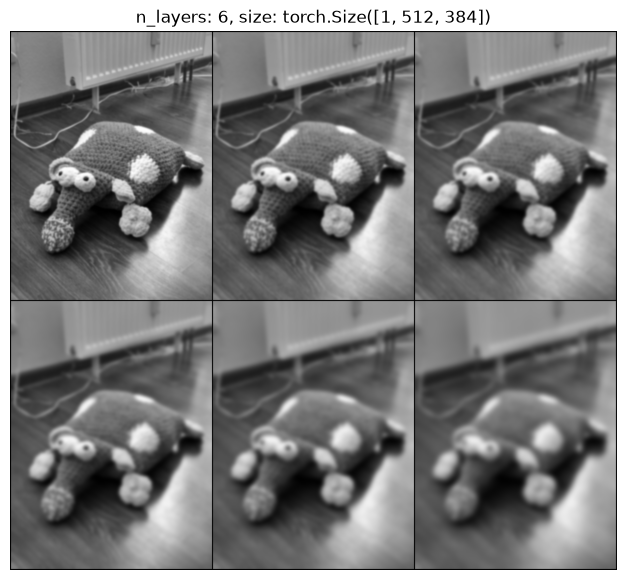

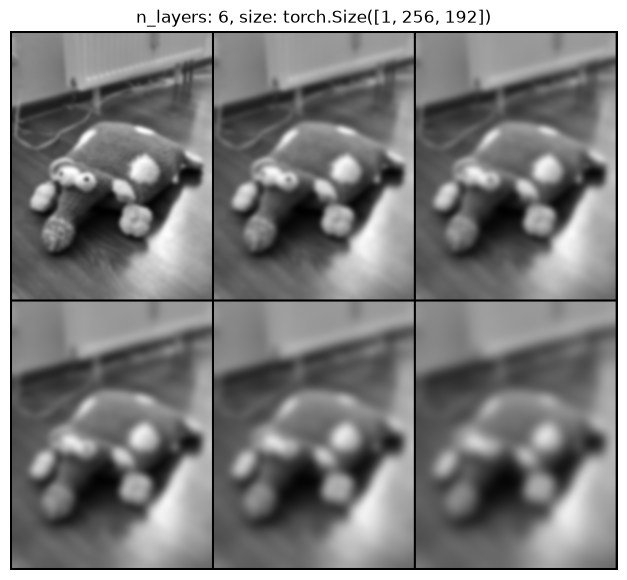

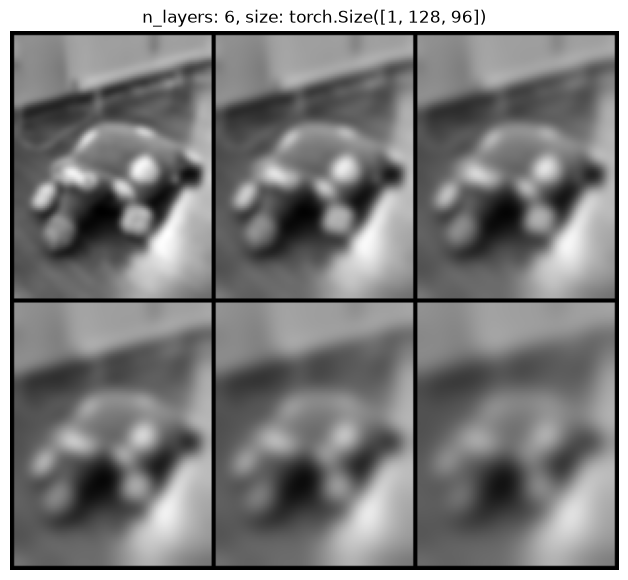

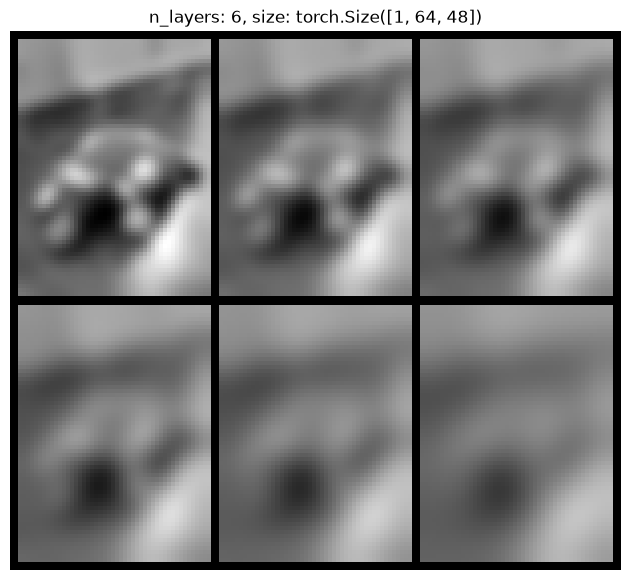

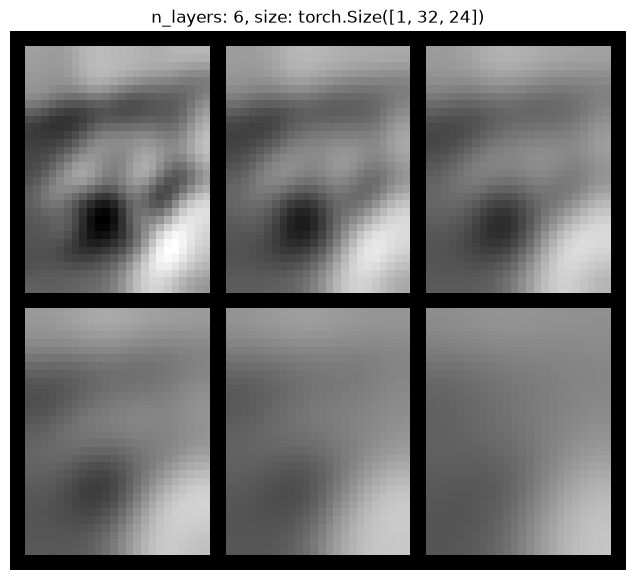

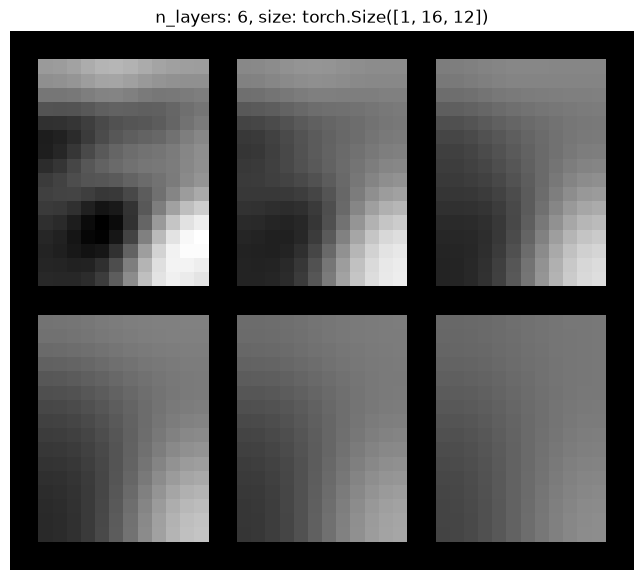

In [386]:
params = SIFTParams()

octaves = build_octaves(image, params)

for octave in octaves:
    batch = torch.stack([t for t in octave.layers])

    grid = vutils.make_grid(batch, nrow=3, padding=2, normalize=True)
    grid = grid.permute(1, 2, 0).numpy()

    plt.figure(figsize=(10, 7))
    plt.title(f"{octave}")
    plt.imshow(grid)
    plt.axis("off")
    plt.show()